Spectrum of Sodium-22

In [10]:
import matplotlib.pyplot as plt
import numpy as np
from lmfit import models

In [11]:
with open("spectrum_leeg_231126.csv", "r") as file:
    full_pulseheight = []
    full_counts = []
    i = 0

    for line in file:
        data = line.split(',')

        if i > 0:
            full_pulseheight.append(float(data[0]))
            full_counts.append(float(data[1]))
        else:
            i+=1


In [12]:
pulseheight = []
counts = []
for i in range(len(full_pulseheight)):
    if full_pulseheight[i] > 0:
        pulseheight.append(full_pulseheight[i])
        counts.append(full_counts[i])

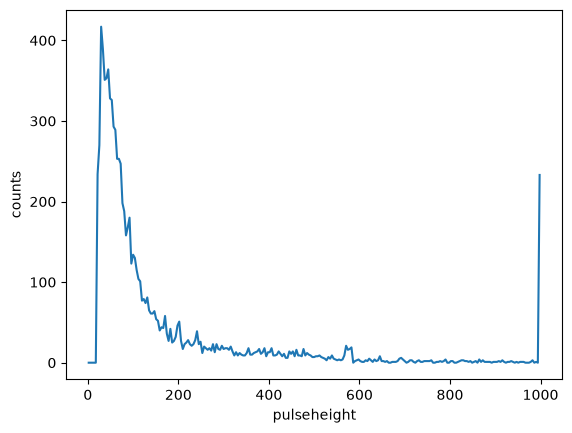

In [13]:
plt.plot(pulseheight, counts)
plt.xlabel("pulseheight")
plt.ylabel("counts")
plt.show()

In [14]:
def lorentzian(x, x0, a, gam ):
  return a * gam**2 / ( gam**2 + ( x - x0 )**2)

def multiple_lorentzian(x, x01, a1, gam1, x02, a2, gam2, x03, a3, gam3):#, x04, a4, gam4):
    return lorentzian(x, x01, a1, gam1) + lorentzian(x, x02, a2, gam2) + lorentzian(x, x03, a3, gam3) #+ lorentzian(x, x04, a4, gam4)

In [15]:
spectrum = models.Model(multiple_lorentzian)
fit_result = spectrum.fit(counts, x=pulseheight, x01=220, a1=200, gam1=10, x02=600, a2=200, gam2=10, x03=260, a3=200, gam3=10)

print(fit_result.fit_report())

[[Model]]
    Model(multiple_lorentzian)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 9366
    # data points      = 255
    # variables        = 9
    chi-square         = 120818.719
    reduced chi-square = 491.133003
    Akaike info crit   = 1588.99966
    Bayesian info crit = 1620.87103
    R-squared          = 0.91875794
[[Variables]]
    x01:   30.6961705 +/- 0.38881448 (1.27%) (init = 220)
    a1:    297.569318 +/- 31.4548167 (10.57%) (init = 200)
    gam1: -4.70552851 +/- 0.93036624 (19.77%) (init = 10)
    x02:   82.9598188 +/- 7.26843943 (8.76%) (init = 600)
    a2:    149.018386 +/- 23.4214384 (15.72%) (init = 200)
    gam2:  40.7665532 +/- 4.83284146 (11.85%) (init = 10)
    x03:   48.4782826 +/- 1.24270219 (2.56%) (init = 260)
    a3:    256.667613 +/- 32.6895688 (12.74%) (init = 200)
    gam3:  13.6871728 +/- 3.50658686 (25.62%) (init = 10)
[[Correlations]] (unreported correlations are < 0.100)
    C(a2, gam3)   = -0.8927
    C(x02, a3)    =

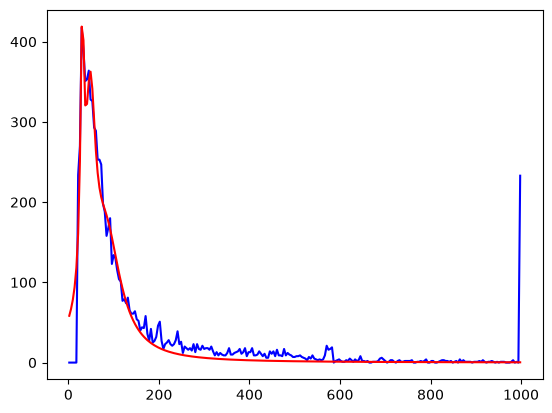

In [16]:
plt.plot(pulseheight, counts, 'b-')
plt.plot(pulseheight, fit_result.best_fit, 'r-')

plt.show()

In [17]:
pulseheight1 = fit_result.params['x01'].value
pulseheight2 = fit_result.params['x02'].value
pulseheight3 = fit_result.params['x03'].value
# pulseheight4 = fit_result.params['x04'].value

err_1 = fit_result.params['x01'].stderr
err_2 = fit_result.params['x02'].stderr
err_3 = fit_result.params['x03'].stderr
# err_4 = fit_result.params['x04'].stderr

print(pulseheight1, err_1)
print(pulseheight2, err_2)
print(pulseheight3, err_3)
# print(pulseheight4, err_4)

30.696170497471403 0.38881447755413473
82.95981881894305 7.268439427376675
48.47828257244525 1.2427021851429647


In [18]:
energy2 = 2.98359957 * pulseheight2 - 65.6423766
energy3 = 2.98359957 * pulseheight3 - 65.6423766

err3 = 2.98359957 * err_3 - 65.6423766
err2 = 2.98359957 * err_2 - 65.6423766

print(energy2, err2, energy3, err3)

181.87650315547637 -43.95626384990791 78.99740643748615 -61.9346508947694
